In [1]:
import sys
from pathlib import Path

# Añadir la raíz del proyecto para importar desde src
sys.path.append(str(Path().resolve().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Entorno cargado correctamente.")

Entorno cargado correctamente.


In [2]:
from src.datos import cargar_y_limpiar_datos

# Cargar y limpiar el dataset de Bank Marketing
X, y = cargar_y_limpiar_datos("../data/bank-full.csv")

print("Dimensiones de X (características):", X.shape)
print("Dimensiones de y (objetivo):", y.shape)

Dimensiones de X (características): (45211, 41)
Dimensiones de y (objetivo): (45211,)


In [3]:
from src.datos import preparar_particiones

# Particionar en 70% Train, 15% Val y 15% Test
X_train, X_val, X_test, y_train, y_val, y_test, scaler = preparar_particiones(X, y)

print("Particiones generadas correctamente:")
print(f"Entrenamiento: {X_train.shape}")
print(f"Validación:    {X_val.shape}")
print(f"Prueba:        {X_test.shape}")

Particiones generadas correctamente:
Entrenamiento: (31650, 41)
Validación:    (6779, 41)
Prueba:        (6782, 41)


In [4]:
conteo_clases = y_train.value_counts()
proporcion_clases = (y_train.value_counts(normalize=True) * 100).round(2)

df_balance = pd.DataFrame({'Conteo': conteo_clases, 'Porcentaje (%)': proporcion_clases})
print("Distribución de la variable objetivo en entrenamiento:")
print(df_balance)

Distribución de la variable objetivo en entrenamiento:
   Conteo  Porcentaje (%)
y                        
0   27947            88.3
1    3703            11.7


**Conclusión:** Hay 3 703 clientes yes (11,7 %) y 27 947 no (88,3 %). El desbalance es marcado: un modelo que siempre prediga no obtendría 88,3 % de exactitud, y esa es la línea base a superar. Por eso la exactitud sola no sirve y se mirarán recall y F1 de la clase yes.

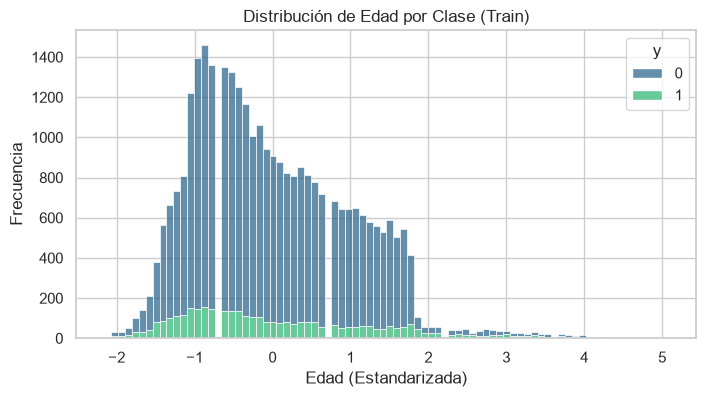

In [5]:
plt.figure(figsize=(8, 4))
sns.histplot(data=X_train, x="age", hue=y_train, multiple="stack", palette="viridis")
plt.title("Distribución de Edad por Clase (Train)")
plt.xlabel("Edad (Estandarizada)")
plt.ylabel("Frecuencia")
plt.show()

**Conclusión:** La distribución de la edad (`age`) estandarizada muestra una concentración similar en ambas clases alrededor de los valores medios, sin una separación lineal evidente entre los clientes que aceptan (`y=1`) y los que rechazan (`y=0`).

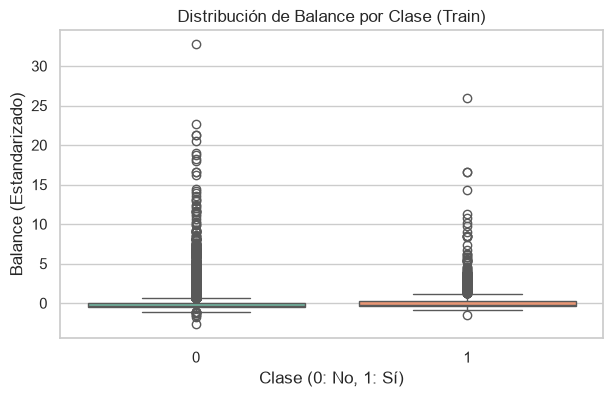

In [6]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=y_train, y=X_train["balance"], hue=y_train, palette="Set2", legend=False)
plt.title("Distribución de Balance por Clase (Train)")
plt.xlabel("Clase (0: No, 1: Sí)")
plt.ylabel("Balance (Estandarizado)")
plt.show()

**Conclusión:** El balance presenta una ligera variación en su distribución entre ambas clases, destacando una alta cantidad de valores atípicos (*outliers*) con saldos positivos elevados en el grupo de no (`0`), así como en menor medida en el grupo de yes (`1`).

In [7]:
cols_numericas = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
df_corr = X_train[cols_numericas].copy()
df_corr['y'] = y_train.values

matriz_corr = df_corr.corr()
print("Correlaciones de variables numéricas respecto a la variable objetivo (y):")
print(matriz_corr['y'].sort_values(ascending=False))

Correlaciones de variables numéricas respecto a la variable objetivo (y):
y           1.000000
previous    0.111648
pdays       0.105578
balance     0.052199
age         0.031036
day        -0.029735
campaign   -0.072094
Name: y, dtype: float64


**Conclusión:** Las correlaciones lineales de las numéricas respecto a `y` muestran valores bajos, siendo `previous` (0,1116) y `pdays` (0,1055) las de mayor relación positiva, mientras que `campaign` muestra una leve correlación negativa (-0,0720). No hay multicolinealidad severa, por lo que se mantienen todas.

In [8]:
print(f"Total de características generadas tras OHE: {X_train.shape[1]}")
print("\nPrimeras 5 filas del conjunto de entrenamiento:")
X_train.head()

Total de características generadas tras OHE: 41

Primeras 5 filas del conjunto de entrenamiento:


,age,balance,day,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
11173,-0.464412,-0.317748,0.260809,-0.567784,-0.411008,-0.300367,False,False,False,True,...,False,True,False,False,False,False,False,False,False,True
30973,0.099190,-0.428907,-0.822456,2.326719,-0.411008,-0.300367,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
36446,-1.309814,-0.348300,-0.581730,0.718662,-0.411008,-0.300367,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
35170,-0.934080,-0.437358,-1.063181,-0.567784,-0.411008,-0.300367,False,False,False,True,...,False,False,False,True,False,False,False,False,False,True
43377,0.099190,0.254624,1.705161,-0.246172,1.408000,0.748406,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


**Conclusión:** La aplicación de One-Hot Encoding expande el conjunto de datos a un total de **41 características** (`X_train.shape[1] = 41`). Las variables categóricas quedan codificadas correctamente y listas, manteniendo la estructura limpia y sin fugas de datos antes de proceder al almacenamiento de los CSVs.

In [9]:
X_train.to_csv("../data/X_train.csv", index=False)
X_val.to_csv("../data/X_val.csv", index=False)
X_test.to_csv("../data/X_test.csv", index=False)
y_train.to_csv("../data/y_train.csv", index=False)
y_val.to_csv("../data/y_val.csv", index=False)
y_test.to_csv("../data/y_test.csv", index=False)

print("¡Etapa 2 finalizada exitosamente! Archivos guardados en la carpeta 'data/'.")

¡Etapa 2 finalizada exitosamente! Archivos guardados en la carpeta 'data/'.
